<a href="https://colab.research.google.com/github/anupbagale/neural-networks-from-scratch/blob/main/notebooks/05_delta_rule.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lesson 5: The Delta Rule and Gradient Descent

Lesson 5 of 8, about 30 minutes.

After this lesson you should be able to:

1. Derive the delta rule as gradient descent on the squared error $E = \tfrac12(d-o)^2$.
2. Train a neuron with a sigmoid activation and read its learning curve.
3. Explain how the learning constant affects speed and stability.
4. Compare the delta rule with the perceptron rule from lesson 4.

You will need: lessons 2 and 4, and the chain rule.

In [1]:
# Setup (works locally and on Google Colab)
try:
    import nnlab
except ImportError:  # not installed yet, e.g. on Colab
    %pip install -q "git+https://github.com/anupbagale/neural-networks-from-scratch"
    import nnlab

import numpy as np
import matplotlib.pyplot as plt
from nnlab.style import apply_style, PALETTE

apply_style()
np.set_printoptions(precision=3, suppress=True)

## Gradient descent on the error

The perceptron rule only knows whether the answer was right or wrong. With a smooth activation we
can also measure how wrong it was. For one pattern define the error

$$E = \tfrac12\,(d - o)^2, \qquad o = f(net), \qquad net = \mathbf{w}^\top\mathbf{x}.$$

Gradient descent takes a small step against the gradient, $\Delta\mathbf{w} = -c\,\nabla_{\mathbf{w}}E$.
By the chain rule,

$$
\frac{\partial E}{\partial \mathbf{w}}
= \frac{\partial E}{\partial o}\,\frac{\partial o}{\partial net}\,\frac{\partial net}{\partial \mathbf{w}}
= -(d - o)\, f'(net)\, \mathbf{x},
$$

which gives the delta rule (Widrow and Hoff, 1960, here with a sigmoid):

$$
\Delta\mathbf{w} = c\,(d - o)\,f'(net)\,\mathbf{x}
= c\,(d - o)\,\tfrac{\lambda}{2}(1 - o^2)\,\mathbf{x}
$$

using the bipolar sigmoid derivative from lesson 2. The term $\delta = (d - o) f'(net)$ gives the
rule its name, and it is the quantity that backpropagation passes backwards in lesson 6.

## Worked example

We use the same training set as in lesson 4 so the two rules can be compared:
$\mathbf{w}^1 = [1,\ -1,\ 0,\ 0.5]$, $c = 0.1$, $\lambda = 1$.

Step 1: $net = 2.5$, $o = \frac{2}{1+e^{-2.5}} - 1 \approx 0.848$,
$f'(net) = \tfrac12(1 - 0.848^2) \approx 0.140$, so
$\Delta\mathbf{w} = 0.1 \cdot (-1 - 0.848) \cdot 0.140 \cdot \mathbf{x}_1 \approx -0.0259\,\mathbf{x}_1$.

In [2]:
from nnlab.learning_rules import delta_rule

w0 = [1, -1, 0, 0.5]
X = [[1, -2, 0, -1],
     [0, 1.5, -0.5, -1],
     [-1, 1, 0.5, -1]]
d = [-1, -1, 1]

one_epoch = delta_rule(w0, X, d, c=0.1, epochs=1)
one_epoch.print_steps(precision=4)

initial w = [ 1.  -1.   0.   0.5]
epoch 1, x1:  net = +2.5000  o = +0.8483  d = -1  ->  w = [ 0.9741 -0.9482  0.      0.5259]
epoch 1, x2:  net = -1.9482  o = -0.7505  d = -1  ->  w = [ 0.9741 -0.9563  0.0027  0.5314]
epoch 1, x3:  net = -2.4604  o = -0.8426  d = +1  ->  w = [ 0.9474 -0.9296  0.0161  0.5046]


In lesson 4 the perceptron made one large jump of $\pm 0.2\,\mathbf{x}$. The delta rule takes small
steps whose size depends on how far $o$ is from $d$ and on how steep the sigmoid is at that point.

## Training until the error is small

In [3]:
trained = delta_rule(w0, X, d, c=0.1, epochs=5000, tol=0.01)
print(f"total error below 0.01 after {trained.n_epochs} epochs")
print("final weights:", trained.weights)

from nnlab.activations import bipolar_sigmoid
print("outputs:", bipolar_sigmoid(np.asarray(X) @ trained.weights), " targets:", d)

total error below 0.01 after 594 epochs
final weights: [-2.997 -0.197  2.901  1.224]
outputs: [-0.957 -0.902  0.908]  targets: [-1, -1, 1]


The outputs get close to $\pm 1$ but never reach them, because a sigmoid only reaches its limits
at $net = \pm\infty$. That is why training stops at a tolerance rather than at zero error.

## The learning constant

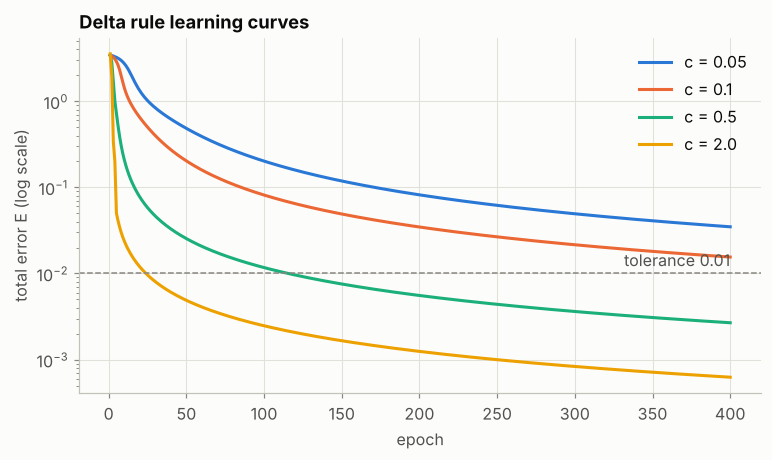

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for c in [0.05, 0.1, 0.5, 2.0]:
    h = delta_rule(w0, X, d, c=c, epochs=400)
    ax.plot(range(1, len(h.epoch_errors) + 1), h.epoch_errors, label=f"c = {c}")
ax.set(yscale="log", xlabel="epoch", ylabel="total error E (log scale)",
       title="Delta rule learning curves")
ax.axhline(0.01, color="#898781", ls="--", lw=1)
ax.text(400, 0.011, "tolerance 0.01", ha="right", va="bottom", color="#52514e")
ax.legend()
plt.show()

A larger $c$ goes down the error surface faster, but each step is a straight-line extrapolation of
a curved surface, so if $c$ is too large the steps overshoot. On this small problem all four values
work. On harder problems a large $c$ can make the error oscillate or grow.

## Perceptron rule and delta rule side by side

| | Perceptron rule | Delta rule |
|---|---|---|
| activation | $\operatorname{sgn}$ | sigmoid |
| update | $c\,(d - o)\,\mathbf{x}$ | $c\,(d - o)\,f'(net)\,\mathbf{x}$ |
| learns from | mistakes only | every pattern, in proportion to the error |
| stops when | there are no mistakes | the error is below a tolerance |
| data that is not separable | never settles | settles at a compromise with the least error |
| extends to hidden layers | no | yes, as backpropagation |

## Exercises

1. Change $\lambda$ to 2 and to 0.5 with `delta_rule(..., lam=...)`. How does the number of
   epochs change, and why?
2. Run the delta rule on the bipolar XOR data from lesson 4 and plot the error. Where does it level off?

**Answers**

<details><summary>Answer</summary>

1. A steeper sigmoid (larger $\lambda$) has a larger derivative near $net = 0$, so early steps are bigger, but it also saturates sooner, after which the steps become very small. Which effect wins is something to measure.
2. The error stops falling at a value above zero. The neuron finds the best line it can, but no single line separates XOR.

</details>

## Summary

- The delta rule is gradient descent on the squared error: Δw = c(d − o)f′(net)x.
- Each update is proportional to the error and to the slope of the activation.
- The learning constant trades speed against stability.
- The error signal δ = (d − o)f′(net) is the building block of backpropagation.

Next: [Lesson 6, Backpropagation on XOR](06_backpropagation_xor.ipynb)

### References

- Widrow, B., & Hoff, M. E. (1960). Adaptive switching circuits. *IRE WESCON Convention Record*, 4, 96–104.
- Zurada, J. M. (1992). *Introduction to Artificial Neural Systems*. West Publishing Company.